# Exploration: the outcome, its family, correlations and PCA


**Question.** Does a shot-quality model need to know who took the shot? This notebook looks at the data before any model: the outcome and its family, which columns move together, and how many principal components hold 90% of the variation. One row is one WNBA 2025 shot. Seed 651.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../shots_with_bios.csv")
y = df["made_flag"]
print("rows, columns:", df.shape)
print("make rate:", round(y.mean(), 4))

rows, columns: (38535, 25)
make rate: 0.4392


## 1. The outcome

`made_flag` is 1 for a made shot and 0 for a miss. Left: how many of each. Right: the make rate by shot distance, since distance is the strongest column I expect to use.

,mean,count
shot_distance,,
0,0.727069,1341
1,0.679021,2779
2,0.618049,3435
3,0.549098,2994
4,0.444184,2132
5,0.417062,1688
6,0.379637,1267
7,0.350402,996
8,0.372981,681


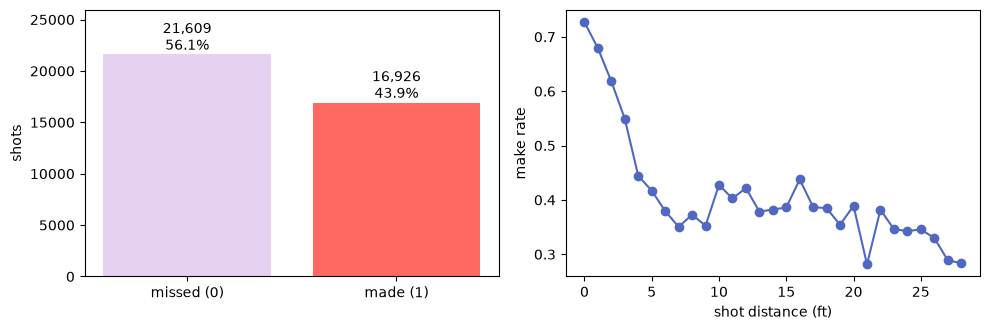

distances with at least 100 shots: 29


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
counts = y.value_counts().sort_index()
ax[0].bar(["missed (0)", "made (1)"], counts.values, color=["#E6D1F2", "#FF6961"])
for i, c in enumerate(counts.values):
    ax[0].text(i, c, f"{c:,}\n{c/len(y):.1%}", ha="center", va="bottom")
ax[0].set_ylim(0, counts.max() * 1.2); ax[0].set_ylabel("shots")
by = df.groupby("shot_distance")["made_flag"].agg(["mean", "count"])
by = by[by["count"] >= 100]                 # keep distances with at least 100 shots
display(by)
ax[1].plot(by.index, by["mean"], "o-", color="#5168C0")
ax[1].set_xlabel("shot distance (ft)"); ax[1].set_ylabel("make rate")
plt.tight_layout(); plt.show()
print("distances with at least 100 shots:", len(by))